In [4]:
!pip install mlxtend; pandas matplotlib

/bin/bash: line 1: pandas: command not found


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

--- Generated Association Rules ---
  antecedents consequents  support  confidence      lift
0    (butter)     (bread)      0.6    1.000000  1.250000
1     (bread)    (butter)      0.6    0.750000  1.250000
2      (eggs)     (bread)      0.4    0.666667  0.833333
3     (bread)      (eggs)      0.4    0.500000  0.833333
4     (bread)      (milk)      0.4    0.500000  0.833333
5      (milk)     (bread)      0.4    0.666667  0.833333
6      (eggs)      (milk)      0.4    0.666667  1.111111
7      (milk)      (eggs)      0.4    0.666667  1.111111


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

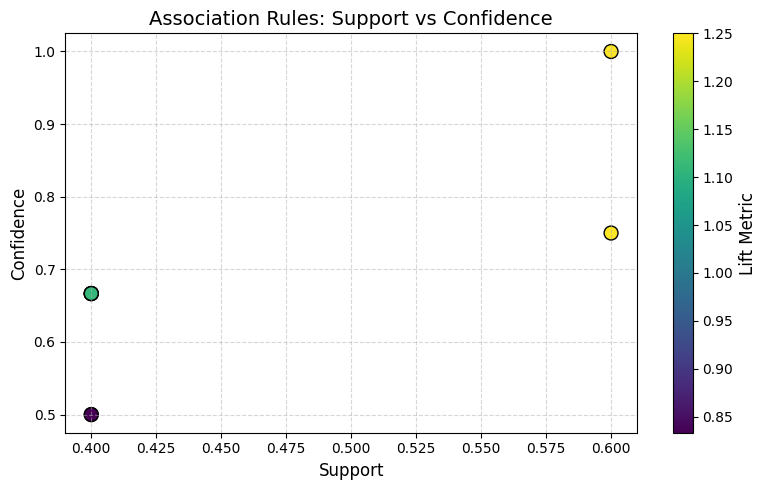

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# 1.  transactional dataset
dataset = [
    ["milk", "bread", "eggs"],
    ["bread", "butter"],
    ["milk", "bread", "butter"],
    ["milk", "eggs"],
    ["bread", "butter", "eggs"],
]

# 2. Data Preprocessing: One-hot encode the transactions
te = TransactionEncoder()
te_ary = te.fit(dataset).transform(dataset)
df = pd.DataFrame(te_ary, columns=te.columns_)

# 3. Generate Frequent Itemsets (Apriori)
min_support_threshold = 0.4
frequent_itemsets = apriori(
    df, min_support=min_support_threshold, use_colnames=True
)

# 4. Apply Rule Mining
rules = association_rules(
    frequent_itemsets, metric="confidence", min_threshold=0.5
)

# --- Print Results to Console ---
print("--- Generated Association Rules ---")
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]])

# 5. Visualization: Plot Support vs Confidence
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    rules["support"],
    rules["confidence"],
    c=rules["lift"],
    cmap="viridis",
    s=100,
    edgecolors="black",
)

# Add labels and styling
plt.title("Association Rules: Support vs Confidence", fontsize=14)
plt.xlabel("Support", fontsize=12)
plt.ylabel("Confidence", fontsize=12)

# Add a color bar to represent the Lift metric
colorbar = plt.colorbar(scatter)
colorbar.set_label("Lift Metric", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
